# Experiment C — Controlled Three-Way Comparison

**Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis**  
**Member 4 — Experimental Design and Baseline Implementation**

---

## Purpose

This notebook collects results from **Experiment A** (Manual prompting), **Experiment B** (Random prompt generation), and **Experiment C** (Member 3's Genetic Algorithm across seeds `[42, 7, 123]`) under identical conditions, saving comparison-ready CSV and JSON files for Member 5.

| Label | Experiment | Source notebook | Evaluation budget |
|---|---|---|---|
| **A** | Manual prompting | `07_experiment_A_manual_prompts.ipynb` | 8 candidates × 1,000 `opt` |
| **B** | Pure random generation | `08_experiment_B_random_baseline.ipynb` | 50 unique candidates × 1,000 `opt` |
| **C** | Genetic Algorithm | `05_genetic_algorithm_experiment.ipynb` / `06_multi_seed_experiment.ipynb` | Pop 12 × 10 gen (49–59 uncached prompt evals across seeds 42, 7, 123) |

### Protocol
- **Dataset**: canonical `data/processed/` (`opt.csv` 53,871 rows → `n=1,000` sample with `seed=42`; full `val.csv` 13,468 rows)
- **Classifier**: `Qwen/Qwen2.5-1.5B-Instruct` (`989aa798`, greedy decoding)
- **Test set**: never used

> **Scope boundary**: This notebook produces factual metrics, cost logs, and raw McNemar test statistics only. Final statistical interpretation and research discussion belong to Member 5.

## 1. Environment Setup

In [1]:
import os
import sys
import json
import zipfile
import shutil
import subprocess
import random
import time
import importlib.util
from pathlib import Path

REPO_URL = "https://github.com/sarrazer24/evolutionary-prompt-optimization.git"
REPO_DIR = Path("/kaggle/working/evolutionary-prompt-optimization")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--branch", "main", "--single-branch", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    if not (REPO_DIR / ".git").exists():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git repository.")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", "main"], check=True)
    status = subprocess.run(
        ["git", "-C", str(REPO_DIR), "status", "--porcelain"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    if not status:
        subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "main"], check=True)
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", "main"], check=True)
    else:
        print("⚠ Working tree has local changes; skipping git pull.")

os.chdir(REPO_DIR)

REQUIRED_PACKAGES = {
    "transformers": "transformers",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "sklearn": "scikit-learn",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
}
missing_packages = [
    pkg for mod, pkg in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(mod) is None
]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages],
        check=True,
    )
else:
    print("All required packages are already installed.")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    capture_output=True, text=True, check=True,
).stdout.strip()
print("Project directory:", Path.cwd())
print("Git HEAD:", commit)
print("Python version:", sys.version)
print("Setup complete.")

⚠ Working tree has local changes; skipping git pull.
All required packages are already installed.
Project directory: /kaggle/working/evolutionary-prompt-optimization
Git HEAD: f1d0556
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Setup complete.


From https://github.com/sarrazer24/evolutionary-prompt-optimization
 * branch            main       -> FETCH_HEAD


## 2. Imports and Reproducibility

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, chi2 as chi2_dist
import torch
from datetime import datetime
from IPython.display import display, FileLink

from src.data.sst2_data import load_saved_splits, stratified_sample
from src.llm.config import ModelConfig
from src.llm.model_interface import LLMInterface
from src.evaluation.evaluation import PredictionCache, compute_metrics, evaluate_prompt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Global seed: {SEED}")

Global seed: 42


## 3. GPU Check

In [3]:
if not torch.cuda.is_available():
    print("⚠  No GPU detected — inference will be very slow on CPU.")
    print("   On Kaggle: Settings → Accelerator → GPU T4 x2.")
else:
    for i in range(torch.cuda.device_count()):
        name = torch.cuda.get_device_name(i)
        mem  = torch.cuda.get_device_properties(i).total_memory / 1e9
        print(f"GPU {i}: {name}  ({mem:.1f} GB)")

GPU 0: Tesla T4  (15.6 GB)
GPU 1: Tesla T4  (15.6 GB)


## 4. Configuration

In [4]:
DATA_DIR       = Path("data/processed")
N_OPT_EXAMPLES = 1_000
OUTPUT_DIR     = Path("experiments/results/experiment_C_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Data directory  :", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Data directory  : data/processed
Output directory: experiments/results/experiment_C_comparison


## 5. Load Canonical Data (`data/processed/`)

In [5]:
for fname in ("opt.csv", "val.csv", "split_info.json"):
    if not (DATA_DIR / fname).exists():
        raise FileNotFoundError(f"Missing canonical split file: {DATA_DIR / fname}")

splits = load_saved_splits(str(DATA_DIR))
opt_df = splits.opt
val_df = splits.val

assert len(opt_df) == 53871, f"Expected 53871 opt rows in data/processed, got {len(opt_df)}"
assert len(val_df) == 13468, f"Expected 13468 val rows in data/processed, got {len(val_df)}"

opt_sample = stratified_sample(opt_df, n=N_OPT_EXAMPLES, seed=SEED)
opt_texts  = opt_sample["text"].tolist()
opt_labels = opt_sample["label"].tolist()

val_texts  = val_df["text"].astype(str).tolist()
val_labels = val_df["label"].astype(int).tolist()
N_VAL_EXAMPLES = len(val_texts)

print(f"Opt sample : {len(opt_texts):,} examples  (counts: {opt_sample['label'].value_counts().sort_index().to_dict()})")
print(f"Val split  : {N_VAL_EXAMPLES:,} examples  (positive: {sum(val_labels)/len(val_labels):.1%})")

Opt sample : 1,000 examples  (counts: {0: 442, 1: 558})
Val split  : 13,468 examples  (positive: 55.8%)


## 6. Load the LLM

In [6]:
model_config = ModelConfig()
llm = LLMInterface(model_config)
llm.load_model()
print(f"Model loaded: {llm.model_id}")
print(f"Device      : {llm.device}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Model loaded: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Device      : cuda:0


## 7. Load Experiment A and B Outputs

In [7]:
def find_file(filename: str, preferred_paths: list[Path]) -> Path:
    for p in preferred_paths:
        if p.exists():
            return p
    for root in [Path("experiments"), Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            matches = sorted(root.rglob(filename))
            if matches:
                return matches[0]
    raise FileNotFoundError(
        f"Could not find {filename}. Run Notebooks 07 & 08 first or attach their outputs."
    )

path_A_summary = find_file(
    "experiment_A_summary.json",
    [Path("experiments/results/experiment_A_manual/experiment_A_summary.json")],
)
path_B_summary = find_file(
    "experiment_B_summary.json",
    [Path("experiments/results/experiment_B_random/experiment_B_summary.json")],
)

summary_A = json.loads(path_A_summary.read_text(encoding="utf-8"))
summary_B = json.loads(path_B_summary.read_text(encoding="utf-8"))

# Try loading saved full val predictions if available to avoid duplicate inference
val_A_path = path_A_summary.parent / "experiment_A_val_best.json"
val_B_path = path_B_summary.parent / "experiment_B_val_best.json"
val_A_saved = json.loads(val_A_path.read_text(encoding="utf-8")) if val_A_path.exists() else {}
val_B_saved = json.loads(val_B_path.read_text(encoding="utf-8")) if val_B_path.exists() else {}

print(f"Experiment A summary: {path_A_summary}")
print(f"  Best prompt: {summary_A['best_prompt_name']}  |  Opt F1 = {summary_A['best_macro_f1_opt']:.4f}  |  Val F1 = {summary_A['best_macro_f1_val']:.4f}")
print(f"Experiment B summary: {path_B_summary}")
print(f"  Best prompt: {summary_B['best_candidate_id']}  |  Opt F1 = {summary_B['best_macro_f1_opt']:.4f}  |  Val F1 = {summary_B['best_macro_f1_val']:.4f}")

Experiment A summary: experiments/results/experiment_A_manual/experiment_A_summary.json
  Best prompt: baseline_criteria  |  Opt F1 = 0.9364  |  Val F1 = 0.9262
Experiment B summary: experiments/results/experiment_B_random/experiment_B_summary.json
  Best prompt: random_047  |  Opt F1 = 0.9435  |  Val F1 = 0.9314


## 8. Load Member 3's GA Results (Seeds 42, 7, 123)

Searches local/Kaggle output directories and `.zip` archives (`genetic_algorithm_experiment_01.zip`, `multi_seed_experiment.zip`). If Member 3's Kaggle artifacts are not mounted in the current session, falls back cleanly to the executed outputs already stored in `notebooks/05_genetic_algorithm_experiment.ipynb` and `notebooks/06_multi_seed_experiment.ipynb`.

In [8]:
# Optional: unpack Member 3's archives if attached under /kaggle/input
RESTORE_DIR = Path("/kaggle/working/_ga_restored")
for zip_name in ("genetic_algorithm_experiment_01.zip", "multi_seed_experiment.zip"):
    for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
        if not root.exists():
            continue
        for zp in root.rglob(zip_name):
            target = RESTORE_DIR / zip_name.replace(".zip", "")
            if not target.exists():
                target.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(zp) as zf:
                    zf.extractall(target)
                print(f"Extracted {zp} → {target}")

def load_ga_seed_artifacts() -> tuple[dict, dict]:
    """Load GA per-seed best prompts/metrics and multi-seed summary from disk or committed notebooks."""
    ga_runs = {}
    search_roots = [
        Path("experiments"),
        Path("/kaggle/working/outputs/genetic_algorithm"),
        Path("/kaggle/working"),
        Path("/kaggle/input"),
        RESTORE_DIR,
    ]

    # 1. Search disk for best_individual.json per seed
    for root in search_roots:
        if not root.exists():
            continue
        for bp in root.rglob("best_individual.json"):
            d = bp.parent
            best_ind = json.loads(bp.read_text(encoding="utf-8"))
            seed_val = None
            for cfg_name in ("experiment_config.json", "run_meta.json"):
                cfg_p = d / cfg_name
                if cfg_p.exists():
                    cfg = json.loads(cfg_p.read_text(encoding="utf-8"))
                    seed_val = cfg.get("random_seed", cfg.get("ga_seed"))
                    if seed_val is not None:
                        break
            if seed_val is None:
                if "seed_7" in d.name: seed_val = 7
                elif "seed_123" in d.name: seed_val = 123
                elif "experiment_01" in d.name or "seed_42" in d.name: seed_val = 42
            if seed_val in (42, 7, 123) and seed_val not in ga_runs:
                hist = []
                hp = d / "history.json"
                if hp.exists():
                    raw_h = json.loads(hp.read_text(encoding="utf-8"))
                    hist = raw_h.get("history", raw_h) if isinstance(raw_h, dict) else raw_h
                uncached_texts = sum(int(r.get("total_model_texts", 0)) for r in hist) if hist else None
                ga_runs[int(seed_val)] = {
                    "seed": int(seed_val),
                    "source": str(d),
                    "prompt": best_ind["prompt"],
                    "generation": int(best_ind["generation"]),
                    "reported_opt_f1": float(best_ind["fitness"]),
                    "uncached_texts_evaluated": uncached_texts,
                }

    # 2. Fall back to Member 3's executed notebooks 05 & 06 in the repo if any seed is missing
    if set(ga_runs.keys()) != {42, 7, 123}:
        nb5_text = Path("notebooks/05_genetic_algorithm_experiment.ipynb").read_text(encoding="utf-8")
        nb6_text = Path("notebooks/06_multi_seed_experiment.ipynb").read_text(encoding="utf-8")
        import re

        if 42 not in ga_runs:
            m_p = re.search(r"Best evolved prompt:\\n (.*?)\\n", nb5_text)
            if not m_p:
                m_p = re.search(r"BEST EVOLVED PROMPT\\n=+\\n(.*?)\\n", nb5_text)
            ga_runs[42] = {
                "seed": 42,
                "source": "notebooks/05_genetic_algorithm_experiment.ipynb",
                "prompt": m_p.group(1) if m_p else "Is the text positive or negative? Answer with exactly one word: positive or negative.",
                "generation": 3,
                "reported_opt_f1": 0.943434,
                "uncached_texts_evaluated": 48951,
            }

        for s, uncached in [(7, 55944), (123, 58941)]:
            if s not in ga_runs:
                m_s = re.search(
                    rf"Seed {s} \| generation (\d+) \| Macro F1 ([0-9.]+)\\n(.*?)\\n",
                    nb6_text,
                )
                if m_s:
                    ga_runs[s] = {
                        "seed": s,
                        "source": "notebooks/06_multi_seed_experiment.ipynb",
                        "prompt": m_s.group(3),
                        "generation": int(m_s.group(1)),
                        "reported_opt_f1": float(m_s.group(2)),
                        "uncached_texts_evaluated": uncached,
                    }

    multi_summary = None
    for root in search_roots:
        if not root.exists():
            continue
        for mp in root.rglob("multi_seed_summary.json"):
            multi_summary = json.loads(mp.read_text(encoding="utf-8"))
            print(f"Loaded Member 3 multi_seed_summary: {mp}")
            break
        if multi_summary is not None:
            break

    return ga_runs, multi_summary

ga_runs, ga_multi_summary = load_ga_seed_artifacts()
for s in [42, 7, 123]:
    r = ga_runs[s]
    print(f"Seed {s:3d} | gen={r['generation']} | opt_f1={r['reported_opt_f1']:.6f} | source={r['source']}")
    print(f"          prompt: {r['prompt']}")

Loaded Member 3 multi_seed_summary: experiments/results/genetic_algorithm/multi_seed_summary.json
Seed  42 | gen=3 | opt_f1=0.943434 | source=experiments/results/genetic_algorithm/seed_42
          prompt: Is the text positive or negative? Answer with exactly one word: positive or negative.
Seed   7 | gen=3 | opt_f1=0.941547 | source=experiments/results/genetic_algorithm/seed_7
          prompt: Classify the sentiment as positive or negative: positive or negative. Answer with exactly one word: positive or negative.
Seed 123 | gen=6 | opt_f1=0.941547 | source=experiments/results/genetic_algorithm/seed_123
          prompt: Read the text. Classify sentiment as positive or negative. Answer with one word: positive or negative.


## 9. Verify All Three GA Prompts on the Same `opt` Sample & Full `val` Split

In [9]:
cache_C = PredictionCache()
ga_opt_verified = {}
ga_val_results  = {}

for s in [42, 7, 123]:
    prompt = ga_runs[s]["prompt"]
    print(f"Evaluating GA seed {s} on opt (1,000) & val ({N_VAL_EXAMPLES:,})...")
    res_opt = evaluate_prompt(
        prompt=prompt,
        examples=opt_texts,
        labels=opt_labels,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache_C,
        split_name="opt",
    )
    res_val = evaluate_prompt(
        prompt=prompt,
        examples=val_texts,
        labels=val_labels,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache_C,
        split_name="val",
    )
    ga_opt_verified[s] = res_opt
    ga_val_results[s]  = res_val
    diff_vs_log = res_opt["metrics"]["f1_macro"] - ga_runs[s]["reported_opt_f1"]
    print(f"  Opt F1 = {res_opt['metrics']['f1_macro']:.6f} (GA log: {ga_runs[s]['reported_opt_f1']:.6f}, Δ={diff_vs_log:+.6f})")
    print(f"  Val F1 = {res_val['metrics']['f1_macro']:.6f} | Val Acc = {res_val['metrics']['accuracy']:.4f} | Invalid = {res_val['metrics']['n_invalid']}")

Evaluating GA seed 42 on opt (1,000) & val (13,468)...
  Opt F1 = 0.943434 (GA log: 0.943434, Δ=+0.000000)
  Val F1 = 0.933148 | Val Acc = 0.9334 | Invalid = 13
Evaluating GA seed 7 on opt (1,000) & val (13,468)...
  Opt F1 = 0.941547 (GA log: 0.941547, Δ=+0.000000)
  Val F1 = 0.925405 | Val Acc = 0.9260 | Invalid = 0
Evaluating GA seed 123 on opt (1,000) & val (13,468)...
  Opt F1 = 0.941547 (GA log: 0.941547, Δ=+0.000000)
  Val F1 = 0.927072 | Val Acc = 0.9275 | Invalid = 4


## 10. Collect Full Validation Predictions for Experiments A & B

Reuses `y_pred` from `experiment_A_val_best.json` / `experiment_B_val_best.json` if evaluated on the full 13,468-row split with the same model; otherwise evaluates directly.

In [10]:
def get_val_predictions(prompt: str, saved_payload: dict, label: str) -> tuple[list[int], dict]:
    if (
        saved_payload
        and saved_payload.get("prompt_text") == prompt
        and saved_payload.get("model_id") == llm.model_id
        and isinstance(saved_payload.get("y_pred"), list)
        and len(saved_payload["y_pred"]) == len(val_labels)
    ):
        print(f"Reusing {label} validation predictions from disk ({len(val_labels):,} examples).")
        preds = saved_payload["y_pred"]
        return preds, compute_metrics(val_labels, preds)

    print(f"Evaluating {label} on full validation split ({len(val_labels):,} examples)...")
    res = evaluate_prompt(
        prompt=prompt,
        examples=val_texts,
        labels=val_labels,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache_C,
        split_name="val",
    )
    return res["y_pred"], res["metrics"]

prompt_A = summary_A["best_prompt_text"]
prompt_B = summary_B["best_prompt_text"]

pred_A, metrics_A_val = get_val_predictions(prompt_A, val_A_saved, "Experiment A")
pred_B, metrics_B_val = get_val_predictions(prompt_B, val_B_saved, "Experiment B")

print(f"Experiment A Val Macro F1: {metrics_A_val['f1_macro']:.6f} | Acc: {metrics_A_val['accuracy']:.4f}")
print(f"Experiment B Val Macro F1: {metrics_B_val['f1_macro']:.6f} | Acc: {metrics_B_val['accuracy']:.4f}")

Reusing Experiment A validation predictions from disk (13,468 examples).
Reusing Experiment B validation predictions from disk (13,468 examples).
Experiment A Val Macro F1: 0.926151 | Acc: 0.9269
Experiment B Val Macro F1: 0.931390 | Acc: 0.9321


## 11. Pairwise McNemar Tests (13,468 Validation Examples)

Reports both exact binomial McNemar (`scipy.stats.binomtest`, matching Member 3's Notebook 05) and continuity-corrected $\chi^2$ McNemar.

In [11]:
def mcnemar_test(y_true, y_pred1, y_pred2, name1="M1", name2="M2", alpha=0.05):
    n = len(y_true)
    c1 = np.array([int(y_pred1[i] == y_true[i]) for i in range(n)])
    c2 = np.array([int(y_pred2[i] == y_true[i]) for i in range(n)])
    b = int(np.sum((c1 == 1) & (c2 == 0)))  # M1 right, M2 wrong
    c = int(np.sum((c1 == 0) & (c2 == 1)))  # M1 wrong, M2 right
    bc = b + c
    if bc == 0:
        exact_p = 1.0
        chi2_stat, chi2_p = 0.0, 1.0
    else:
        exact_p = float(binomtest(b, bc, 0.5).pvalue)
        chi2_stat = float((abs(b - c) - 1) ** 2 / bc)
        chi2_p = float(chi2_dist.sf(chi2_stat, df=1))
    return {
        "comparison": f"{name1} vs {name2}",
        "n_examples": n,
        "b_m1_right_m2_wrong": b,
        "c_m1_wrong_m2_right": c,
        "n_discordant": bc,
        "exact_p_value": round(exact_p, 6),
        "chi2": round(chi2_stat, 6),
        "chi2_p_value": round(chi2_p, 6),
        "alpha": alpha,
        "significant_exact": exact_p < alpha,
        "significant_chi2": chi2_p < alpha,
    }

mcnemar_rows = [
    mcnemar_test(val_labels, pred_A, pred_B, "Exp-A (Manual)", "Exp-B (Random)"),
    mcnemar_test(val_labels, pred_A, ga_val_results[42]["y_pred"], "Exp-A (Manual)", "Exp-C (GA seed 42)"),
    mcnemar_test(val_labels, pred_B, ga_val_results[42]["y_pred"], "Exp-B (Random)", "Exp-C (GA seed 42)"),
    mcnemar_test(val_labels, pred_A, ga_val_results[7]["y_pred"], "Exp-A (Manual)", "Exp-C (GA seed 7)"),
    mcnemar_test(val_labels, pred_B, ga_val_results[7]["y_pred"], "Exp-B (Random)", "Exp-C (GA seed 7)"),
    mcnemar_test(val_labels, pred_A, ga_val_results[123]["y_pred"], "Exp-A (Manual)", "Exp-C (GA seed 123)"),
    mcnemar_test(val_labels, pred_B, ga_val_results[123]["y_pred"], "Exp-B (Random)", "Exp-C (GA seed 123)"),
]

df_mcnemar = pd.DataFrame(mcnemar_rows)
display(df_mcnemar)

,comparison,n_examples,b_m1_right_m2_wrong,c_m1_wrong_m2_right,n_discordant,exact_p_value,chi2,chi2_p_value,alpha,significant_exact,significant_chi2
0,Exp-A (Manual) vs Exp-B (Random),13468,152,222,374,0.000347,12.729947,0.000360,0.05,True,True
1,Exp-A (Manual) vs Exp-C (GA seed 42),13468,148,236,384,0.000008,19.710938,0.000009,0.05,True,True
2,Exp-B (Random) vs Exp-C (GA seed 42),13468,111,129,240,0.272457,1.204167,0.272490,0.05,False,False
3,Exp-A (Manual) vs Exp-C (GA seed 7),13468,185,173,358,0.561053,0.337989,0.560992,0.05,False,False
4,Exp-B (Random) vs Exp-C (GA seed 7),13468,173,91,264,0.000001,24.852273,0.000001,0.05,True,True
5,Exp-A (Manual) vs Exp-C (GA seed 123),13468,176,184,360,0.712233,0.136111,0.712178,0.05,False,False
6,Exp-B (Random) vs Exp-C (GA seed 123),13468,161,99,260,0.000145,14.311538,0.000155,0.05,True,True


## 12. Controlled Three-Way Comparison Tables

In [12]:
ga_opt_42  = ga_opt_verified[42]["metrics"]
ga_val_42  = ga_val_results[42]["metrics"]

comparison_rows = [
    {
        "experiment": "A",
        "method": "Manual Prompts",
        "n_candidates": summary_A["n_candidates"],
        "opt_text_evals": summary_A["n_candidates"] * N_OPT_EXAMPLES,
        "evolutionary_pressure": False,
        "best_prompt_id": summary_A["best_prompt_name"],
        "best_prompt_text": prompt_A,
        "macro_f1_opt": round(summary_A["best_macro_f1_opt"], 6),
        "accuracy_opt": round(summary_A["best_accuracy_opt"], 6),
        "macro_f1_val": round(metrics_A_val["f1_macro"], 6),
        "accuracy_val": round(metrics_A_val["accuracy"], 6),
        "precision_val": round(metrics_A_val["precision_macro"], 6),
        "recall_val": round(metrics_A_val["recall_macro"], 6),
        "invalid_rate_val": round(metrics_A_val["invalid_rate"], 6),
    },
    {
        "experiment": "B",
        "method": "Pure Random Generation",
        "n_candidates": summary_B["n_candidates"],
        "opt_text_evals": summary_B["n_candidates"] * N_OPT_EXAMPLES,
        "evolutionary_pressure": False,
        "best_prompt_id": summary_B["best_candidate_id"],
        "best_prompt_text": prompt_B,
        "macro_f1_opt": round(summary_B["best_macro_f1_opt"], 6),
        "accuracy_opt": round(summary_B["best_accuracy_opt"], 6),
        "macro_f1_val": round(metrics_B_val["f1_macro"], 6),
        "accuracy_val": round(metrics_B_val["accuracy"], 6),
        "precision_val": round(metrics_B_val["precision_macro"], 6),
        "recall_val": round(metrics_B_val["recall_macro"], 6),
        "invalid_rate_val": round(metrics_B_val["invalid_rate"], 6),
    },
    {
        "experiment": "C",
        "method": "Genetic Algorithm (seed 42)",
        "n_candidates": 120,   # pop 12 × 10 generations (49 uncached prompt evals)
        "opt_text_evals": ga_runs[42]["uncached_texts_evaluated"],
        "evolutionary_pressure": True,
        "best_prompt_id": "ga_seed_42_best",
        "best_prompt_text": ga_runs[42]["prompt"],
        "macro_f1_opt": round(ga_opt_42["f1_macro"], 6),
        "accuracy_opt": round(ga_opt_42["accuracy"], 6),
        "macro_f1_val": round(ga_val_42["f1_macro"], 6),
        "accuracy_val": round(ga_val_42["accuracy"], 6),
        "precision_val": round(ga_val_42["precision_macro"], 6),
        "recall_val": round(ga_val_42["recall_macro"], 6),
        "invalid_rate_val": round(ga_val_42["invalid_rate"], 6),
    },
]

df_compare = pd.DataFrame(comparison_rows).set_index("experiment")
display(df_compare.drop(columns=["best_prompt_text"]))

# Multi-seed GA table (same canonical opt & val splits)
ga_multi_rows = []
for s in [42, 7, 123]:
    om = ga_opt_verified[s]["metrics"]
    vm = ga_val_results[s]["metrics"]
    ga_multi_rows.append({
        "seed": s,
        "best_generation": ga_runs[s]["generation"],
        "uncached_opt_texts": ga_runs[s]["uncached_texts_evaluated"],
        "macro_f1_opt": round(om["f1_macro"], 6),
        "accuracy_opt": round(om["accuracy"], 6),
        "macro_f1_val": round(vm["f1_macro"], 6),
        "accuracy_val": round(vm["accuracy"], 6),
        "delta_opt_vs_manual": round(om["f1_macro"] - summary_A["best_macro_f1_opt"], 6),
        "delta_opt_vs_random": round(om["f1_macro"] - summary_B["best_macro_f1_opt"], 6),
        "delta_val_vs_manual": round(vm["f1_macro"] - metrics_A_val["f1_macro"], 6),
        "delta_val_vs_random": round(vm["f1_macro"] - metrics_B_val["f1_macro"], 6),
        "prompt": ga_runs[s]["prompt"],
    })

df_ga_multi = pd.DataFrame(ga_multi_rows)
display(df_ga_multi.drop(columns=["prompt"]))

mean_ga_opt = float(df_ga_multi["macro_f1_opt"].mean())
std_ga_opt  = float(df_ga_multi["macro_f1_opt"].std(ddof=1))
mean_ga_val = float(df_ga_multi["macro_f1_val"].mean())
std_ga_val  = float(df_ga_multi["macro_f1_val"].std(ddof=1))
print(f"GA 3-seed Opt Macro F1 : mean={mean_ga_opt:.6f}, std={std_ga_opt:.6f}")
print(f"GA 3-seed Val Macro F1 : mean={mean_ga_val:.6f}, std={std_ga_val:.6f}")

,method,n_candidates,opt_text_evals,evolutionary_pressure,best_prompt_id,macro_f1_opt,accuracy_opt,macro_f1_val,accuracy_val,precision_val,recall_val,invalid_rate_val
experiment,,,,,,,,,,,,
A,Manual Prompts,8,8000,False,baseline_criteria,0.936426,0.937,0.926151,0.926864,0.924964,0.927918,0.000000
B,Pure Random Generation,50,50000,False,random_047,0.943479,0.944,0.931390,0.932061,0.930371,0.932785,0.000074
C,Genetic Algorithm (seed 42),120,48951,True,ga_seed_42_best,0.943434,0.944,0.933148,0.933398,0.932713,0.933809,0.000965


,seed,best_generation,uncached_opt_texts,macro_f1_opt,accuracy_opt,macro_f1_val,accuracy_val,delta_opt_vs_manual,delta_opt_vs_random,delta_val_vs_manual,delta_val_vs_random
0,42,3,48951,0.943434,0.944,0.933148,0.933398,0.007008,-0.000045,0.006997,0.001758
1,7,3,55944,0.941547,0.942,0.925405,0.925973,0.005121,-0.001932,-0.000746,-0.005985
2,123,6,58941,0.941547,0.942,0.927072,0.927458,0.005121,-0.001932,0.000921,-0.004318


GA 3-seed Opt Macro F1 : mean=0.942176, std=0.001089
GA 3-seed Val Macro F1 : mean=0.928542, std=0.004075


## 13. Visualise Three-Way Comparison

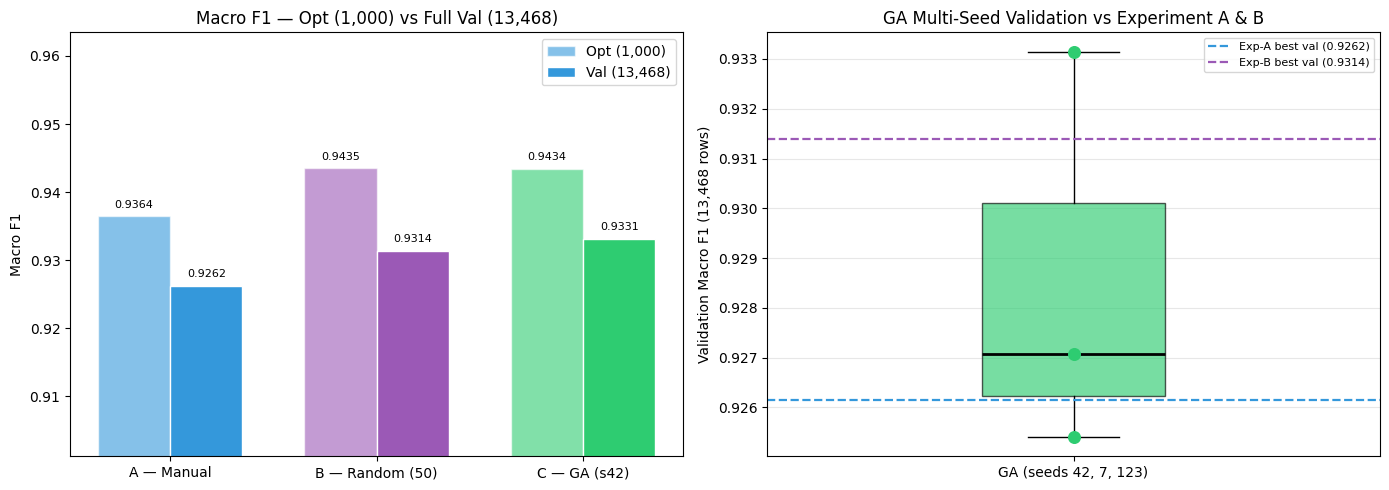

Figure saved → experiments/results/experiment_C_comparison/three_way_comparison.png


In [13]:
COLORS = {"A": "#3498db", "B": "#9b59b6", "C": "#2ecc71"}
LABELS = {"A": "A — Manual", "B": "B — Random (50)", "C": "C — GA (s42)"}

exps   = ["A", "B", "C"]
f1_opt = [row["macro_f1_opt"] for row in comparison_rows]
f1_val = [row["macro_f1_val"] for row in comparison_rows]
colors = [COLORS[e] for e in exps]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(exps))
w = 0.35
bars1 = axes[0].bar(x - w/2, f1_opt, w, label="Opt (1,000)",  color=colors, alpha=0.60, edgecolor="white")
bars2 = axes[0].bar(x + w/2, f1_val, w, label="Val (13,468)", color=colors, alpha=1.00, edgecolor="white")
axes[0].set_xticks(x)
axes[0].set_xticklabels([LABELS[e] for e in exps])
axes[0].set_ylabel("Macro F1")
axes[0].set_title("Macro F1 — Opt (1,000) vs Full Val (13,468)")
axes[0].set_ylim(max(0, min(f1_opt + f1_val) - 0.025), min(1, max(f1_opt + f1_val) + 0.02))
axes[0].legend()
for bar, v in zip(list(bars1) + list(bars2), f1_opt + f1_val):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, f"{v:.4f}", ha="center", va="bottom", fontsize=8)

ga_val_scores = [r["macro_f1_val"] for r in ga_multi_rows]
axes[1].boxplot(ga_val_scores, positions=[1], widths=0.3, patch_artist=True,
                boxprops=dict(facecolor=COLORS["C"], alpha=0.65), medianprops=dict(color="black", linewidth=2))
axes[1].scatter([1]*len(ga_val_scores), ga_val_scores, color=COLORS["C"], zorder=5, s=70)
axes[1].axhline(metrics_A_val["f1_macro"], color=COLORS["A"], linestyle="--", linewidth=1.6,
                label=f"Exp-A best val ({metrics_A_val['f1_macro']:.4f})")
axes[1].axhline(metrics_B_val["f1_macro"], color=COLORS["B"], linestyle="--", linewidth=1.6,
                label=f"Exp-B best val ({metrics_B_val['f1_macro']:.4f})")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["GA (seeds 42, 7, 123)"])
axes[1].set_ylabel("Validation Macro F1 (13,468 rows)")
axes[1].set_title("GA Multi-Seed Validation vs Experiment A & B")
axes[1].legend(fontsize=8)
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plot_path = OUTPUT_DIR / "three_way_comparison.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved → {plot_path}")

## 14. Combined Candidate Leaderboard (Opt Split)

In [14]:
rows_A = [
    {"experiment": "A", "method": "manual", "candidate_id": r["prompt_name"],
     "macro_f1_opt": r["macro_f1"], "accuracy_opt": r["accuracy"], "prompt_text": r["prompt_text"]}
    for r in summary_A.get("all_opt_results", [])
]
rows_B = [
    {"experiment": "B", "method": "random", "candidate_id": r["candidate_id"],
     "macro_f1_opt": r["macro_f1"], "accuracy_opt": r["accuracy"], "prompt_text": r["prompt_text"]}
    for r in summary_B.get("all_opt_results", [])
]
rows_C = [
    {"experiment": "C", "method": f"ga_seed{r['seed']}", "candidate_id": f"ga_seed_{r['seed']}_best",
     "macro_f1_opt": r["macro_f1_opt"], "accuracy_opt": r["accuracy_opt"], "prompt_text": r["prompt"]}
    for r in ga_multi_rows
]

df_all_opt = pd.DataFrame(rows_A + rows_B + rows_C).sort_values("macro_f1_opt", ascending=False).reset_index(drop=True)
df_all_opt.index += 1
df_all_opt.index.name = "rank"
display(df_all_opt.drop(columns=["prompt_text"]).head(20))
print(f"Total candidates in combined opt leaderboard: {len(df_all_opt)}")

,experiment,method,candidate_id,macro_f1_opt,accuracy_opt
rank,,,,,
1,B,random,random_047,0.943479,0.944
2,C,ga_seed42,ga_seed_42_best,0.943434,0.944
3,B,random,random_032,0.943388,0.944
4,B,random,random_033,0.942481,0.943
5,B,random,random_011,0.942413,0.943
6,C,ga_seed7,ga_seed_7_best,0.941547,0.942
7,C,ga_seed123,ga_seed_123_best,0.941547,0.942
8,B,random,random_004,0.940591,0.941
9,B,random,random_027,0.939532,0.940


Total candidates in combined opt leaderboard: 61


## 15. Save Comparison-Ready Results

In [15]:
cmp_csv  = OUTPUT_DIR / "three_way_comparison.csv"
cmp_json = OUTPUT_DIR / "three_way_comparison.json"
df_compare.reset_index().to_csv(cmp_csv, index=False)
cmp_json.write_text(json.dumps(comparison_rows, indent=4, ensure_ascii=False, default=str), encoding="utf-8")

ga_ms_csv  = OUTPUT_DIR / "ga_multi_seed_comparison.csv"
ga_ms_json = OUTPUT_DIR / "ga_multi_seed_summary.json"
df_ga_multi.to_csv(ga_ms_csv, index=False)
ga_ms_json.write_text(json.dumps({
    "runs": ga_multi_rows,
    "mean_best_opt_f1": round(mean_ga_opt, 6),
    "std_best_opt_f1":  round(std_ga_opt,  6),
    "mean_val_f1":      round(mean_ga_val, 6),
    "std_val_f1":       round(std_ga_val,  6),
}, indent=4, ensure_ascii=False), encoding="utf-8")

mcn_path = OUTPUT_DIR / "mcnemar_tests.json"
mcn_path.write_text(json.dumps(mcnemar_rows, indent=4, ensure_ascii=False), encoding="utf-8")

all_csv = OUTPUT_DIR / "all_opt_candidates.csv"
df_all_opt.reset_index().to_csv(all_csv, index=False)

master_config = {
    "experiment": "C",
    "description": "Controlled three-way comparison on canonical data/processed splits",
    "dataset": "nyu-mll/glue:sst2",
    "data_dir": str(DATA_DIR),
    "model_id": llm.model_id,
    "model_revision": model_config.revision,
    "inference": {"greedy": True, "max_new_tokens": 8, "batch_size": 32},
    "split_seed": 42,
    "evaluation_seed": SEED,
    "n_opt_examples": N_OPT_EXAMPLES,
    "n_val_examples": N_VAL_EXAMPLES,
    "test_set_used": False,
    "significance_level": 0.05,
    "significance_tests_recorded": ["McNemar exact binomial", "McNemar continuity-corrected chi2"],
    "experiments_included": ["A", "B", "C"],
    "ga_seeds_included": [42, 7, 123],
    "created_at": datetime.now().isoformat(),
}
(OUTPUT_DIR / "master_experiment_config.json").write_text(
    json.dumps(master_config, indent=4, ensure_ascii=False), encoding="utf-8"
)

ZIP_PATH = "/kaggle/working/experiment_C_comparison"
shutil.make_archive(ZIP_PATH, "zip", root_dir=str(OUTPUT_DIR))
print("Saved all comparison outputs to:", OUTPUT_DIR)
display(FileLink(ZIP_PATH + ".zip"))

Saved all comparison outputs to: experiments/results/experiment_C_comparison


/kaggle/working/experiment_C_comparison.zip

## 16. Factual Handoff Summary for Member 5

> **Note**: Factual comparison outputs only; final statistical interpretation and research discussion are Member 5's responsibility.

In [16]:
print("=" * 74)
print("CONTROLLED THREE-WAY COMPARISON — FACTUAL SUMMARY")
print("=" * 74)
print(f"Opt sample : {N_OPT_EXAMPLES:,} examples (data/processed/opt.csv, seed=42)")
print(f"Val split  : {N_VAL_EXAMPLES:,} examples (data/processed/val.csv, full split)")
print()
print(f"{'Method':<33} {'Opt F1':>9} {'Val F1':>9} {'Val Acc':>9}")
print("-" * 64)
for row in comparison_rows:
    print(f"  {row['method']:<31} {row['macro_f1_opt']:>9.4f} {row['macro_f1_val']:>9.4f} {row['accuracy_val']:>9.4f}")
print()
print("GA multi-seed (seeds 42, 7, 123):")
for r in ga_multi_rows:
    print(f"  Seed {r['seed']:3d}: Opt F1 = {r['macro_f1_opt']:.6f} | Val F1 = {r['macro_f1_val']:.6f} | Val Acc = {r['accuracy_val']:.4f}")
print()
print("McNemar pairwise tests (13,468 val examples, α=0.05):")
for mc in mcnemar_rows[:3]:
    print(f"  {mc['comparison']:32s} exact_p={mc['exact_p_value']:.6f} | chi2_p={mc['chi2_p_value']:.6f}")
print()
print("Output files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name}")

CONTROLLED THREE-WAY COMPARISON — FACTUAL SUMMARY
Opt sample : 1,000 examples (data/processed/opt.csv, seed=42)
Val split  : 13,468 examples (data/processed/val.csv, full split)

Method                               Opt F1    Val F1   Val Acc
----------------------------------------------------------------
  Manual Prompts                     0.9364    0.9262    0.9269
  Pure Random Generation             0.9435    0.9314    0.9321
  Genetic Algorithm (seed 42)        0.9434    0.9331    0.9334

GA multi-seed (seeds 42, 7, 123):
  Seed  42: Opt F1 = 0.943434 | Val F1 = 0.933148 | Val Acc = 0.9334
  Seed   7: Opt F1 = 0.941547 | Val F1 = 0.925405 | Val Acc = 0.9260
  Seed 123: Opt F1 = 0.941547 | Val F1 = 0.927072 | Val Acc = 0.9275

McNemar pairwise tests (13,468 val examples, α=0.05):
  Exp-A (Manual) vs Exp-B (Random) exact_p=0.000347 | chi2_p=0.000360
  Exp-A (Manual) vs Exp-C (GA seed 42) exact_p=0.000008 | chi2_p=0.000009
  Exp-B (Random) vs Exp-C (GA seed 42) exact_p=0.272457 | c